In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv")

df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
df.shape

(891, 12)

In [4]:
df.columns

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='str')

In [5]:
df.dtypes

PassengerId      int64
Survived         int64
Pclass           int64
Name               str
Sex                str
Age            float64
SibSp            int64
Parch            int64
Ticket             str
Fare           float64
Cabin              str
Embarked           str
dtype: object

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [7]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [8]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [9]:
df['Age'] = df['Age'].fillna(df['Age'].median())

df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])

df.drop('Cabin', axis=1, inplace=True)

df.isnull().sum()

PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64

In [11]:
cat_cols = df.select_dtypes(include=['str', 'object']).columns

print(cat_cols)

Index(['Name', 'Sex', 'Ticket', 'Embarked'], dtype='str')


In [14]:
for col in cat_cols:
    df[col] = df[col].astype('category').cat.codes

df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked
0,1,0,3,108,1,22.0,1,0,523,7.2500,2
1,2,1,1,190,0,38.0,1,0,596,71.2833,0
2,3,1,3,353,0,26.0,0,0,669,7.9250,2
3,4,1,1,272,0,35.0,1,0,49,53.1000,2
4,5,0,3,15,1,35.0,0,0,472,8.0500,2


In [15]:
df = pd.read_csv("https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv")

df['Age'] = df['Age'].fillna(df['Age'].median())

df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])

df.drop('Cabin', axis=1, inplace=True)

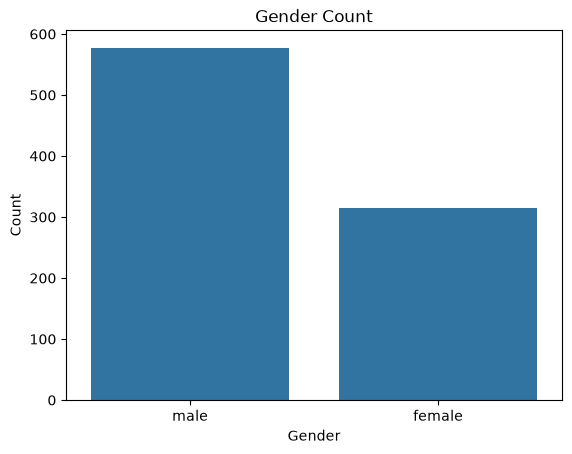

In [16]:
sns.countplot(data=df, x='Sex')
plt.title("Gender Count")
plt.xlabel("Gender")
plt.ylabel("Count")
plt.show()

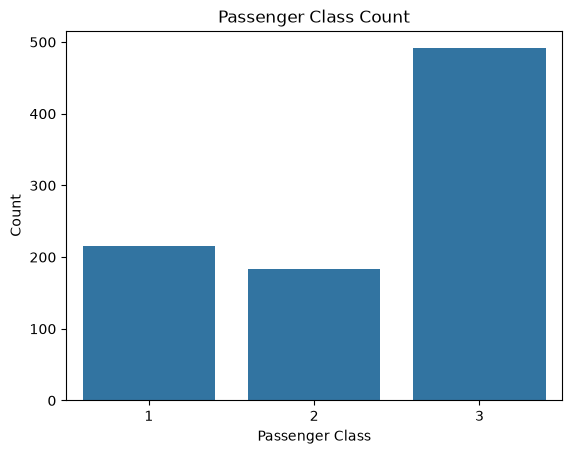

In [17]:
sns.countplot(data=df, x='Pclass')
plt.title("Passenger Class Count")
plt.xlabel("Passenger Class")
plt.ylabel("Count")
plt.show()

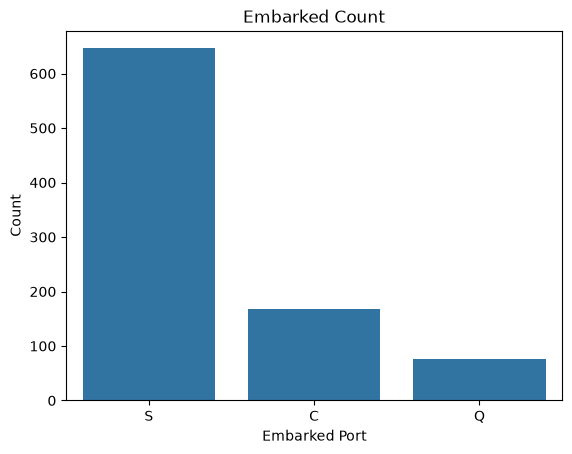

In [18]:
sns.countplot(data=df, x='Embarked')
plt.title("Embarked Count")
plt.xlabel("Embarked Port")
plt.ylabel("Count")
plt.show()

In [19]:
print("Gender Frequency")
print(df['Sex'].value_counts())

print("Passenger Class Frequency")
print(df['Pclass'].value_counts())

print("Embarked Frequency")
print(df['Embarked'].value_counts())

Gender Frequency
Sex
male      577
female    314
Name: count, dtype: int64
Passenger Class Frequency
Pclass
3    491
1    216
2    184
Name: count, dtype: int64
Embarked Frequency
Embarked
S    646
C    168
Q     77
Name: count, dtype: int64


In [20]:
print("Gender Percentage")
print(df['Sex'].value_counts(normalize=True) * 100)

print("Passenger Class Percentage")
print(df['Pclass'].value_counts(normalize=True) * 100)

print("Embarked Percentage")
print(df['Embarked'].value_counts(normalize=True) * 100)

Gender Percentage
Sex
male      64.758698
female    35.241302
Name: proportion, dtype: float64
Passenger Class Percentage
Pclass
3    55.106622
1    24.242424
2    20.650954
Name: proportion, dtype: float64
Embarked Percentage
Embarked
S    72.502806
C    18.855219
Q     8.641975
Name: proportion, dtype: float64


In [21]:
print("Most Common Gender:", df['Sex'].mode()[0])

print("Most Common Passenger Class:", df['Pclass'].mode()[0])

print("Most Common Embarked Port:", df['Embarked'].mode()[0])

Most Common Gender: male
Most Common Passenger Class: 3
Most Common Embarked Port: S


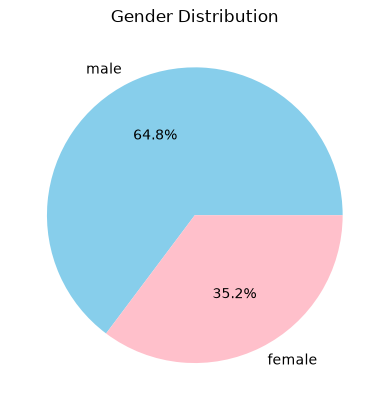

In [22]:
df['Sex'].value_counts().plot.pie(autopct='%1.1f%%', colors=['skyblue', 'pink'])

plt.title("Gender Distribution")
plt.ylabel("")
plt.show()

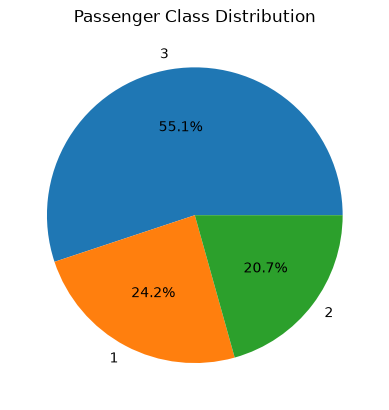

In [23]:
df['Pclass'].value_counts().plot.pie(autopct='%1.1f%%')

plt.title("Passenger Class Distribution")
plt.ylabel("")
plt.show()

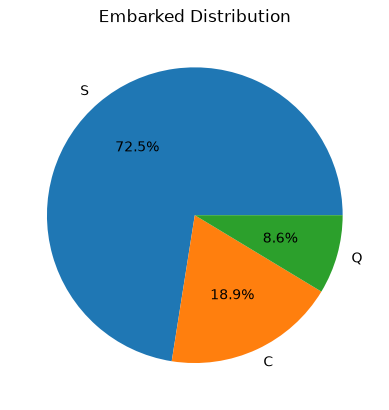

In [24]:
df['Embarked'].value_counts().plot.pie(autopct='%1.1f%%')

plt.title("Embarked Distribution")
plt.ylabel("")
plt.show()

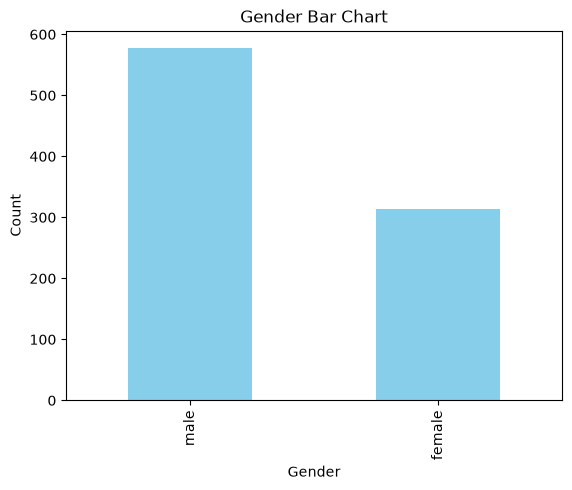

In [26]:
df['Sex'].value_counts().plot.bar(color='skyblue')

plt.title("Gender Bar Chart")
plt.xlabel("Gender")
plt.ylabel("Count")
plt.show()

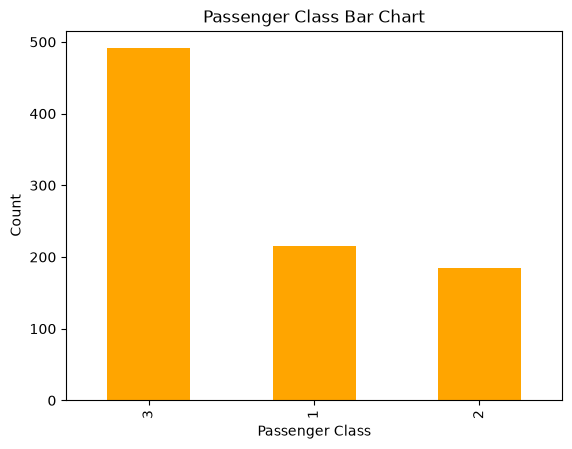

In [27]:
df['Pclass'].value_counts().plot.bar(color='orange')

plt.title("Passenger Class Bar Chart")
plt.xlabel("Passenger Class")
plt.ylabel("Count")
plt.show()

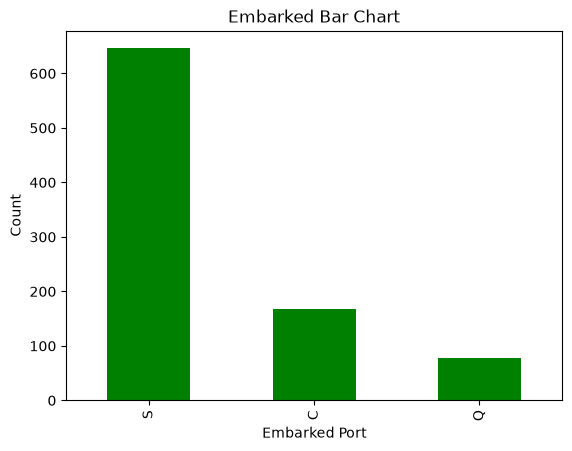

In [28]:
df['Embarked'].value_counts().plot.bar(color='green')

plt.title("Embarked Bar Chart")
plt.xlabel("Embarked Port")
plt.ylabel("Count")
plt.show()

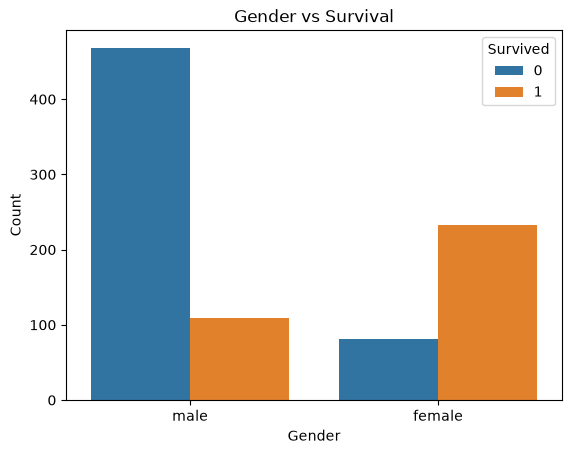

In [29]:
sns.countplot(data=df, x='Sex', hue='Survived')

plt.title("Gender vs Survival")
plt.xlabel("Gender")
plt.ylabel("Count")
plt.show()

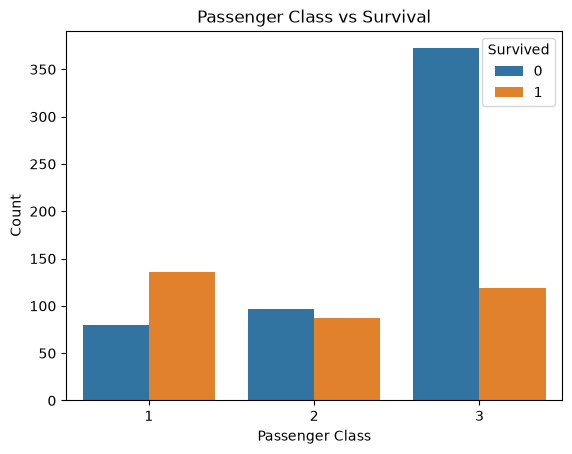

In [31]:
sns.countplot(data=df, x='Pclass', hue='Survived')

plt.title("Passenger Class vs Survival")
plt.xlabel("Passenger Class")
plt.ylabel("Count")
plt.show()

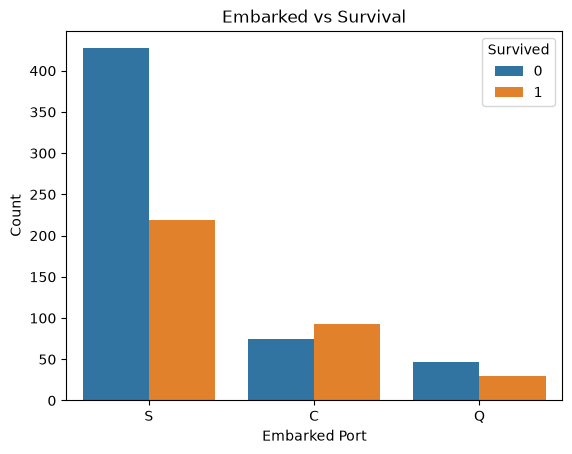

In [32]:
sns.countplot(data=df, x='Embarked', hue='Survived')

plt.title("Embarked vs Survival")
plt.xlabel("Embarked Port")
plt.ylabel("Count")
plt.show()

In [33]:
summary = pd.DataFrame({
    'Frequency': df['Sex'].value_counts(),
    'Percentage': df['Sex'].value_counts(normalize=True) * 100
})

print(summary)

        Frequency  Percentage
Sex                          
male          577   64.758698
female        314   35.241302
